# Seafloor detection

This notebook demonstrates how to:
- Load and preprocess echosounder data using echopype
- Detect the seafloor using two methods with detect_seafloor (basic thresholding and the Blackwell method)
- Export and visualise the detected bottom line with echoregions
- Apply the seafloor mask to the Sv data using apply_mask
- Compute and visualise the mean volume backscattering strength (MVBS) from the masked data


For reproducibility, we first display the Python and package versions, along with information about the runtime environment.

In [1]:
import sys
import platform
import os
import psutil

import echopype as ep
import xarray as xr
import numpy as np
import dask

print(f"Python: {sys.version.split()[0]}")
print(f"Echopype: {ep.__version__}")
print(f"Xarray: {xr.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Dask: {dask.__version__}")

print(f"\nOS: {platform.system()}")
print(f"Logical CPUs: {os.cpu_count()}")
print(f"Total RAM: {psutil.virtual_memory().total / 1024**3:.1f} GiB")

Python: 3.13.14
Echopype: 0.12.1.dev16+g52c4301f6.d20261118
Xarray: 2026.7.0
NumPy: 2.5.1
Dask: 2026.7.1

OS: Windows
Logical CPUs: 16
Total RAM: 63.7 GiB


For readability, we customize the warning format to display warning messages without local file paths.

In [ ]:
import warnings

# display warnings without local file paths
def format_warning(message, category, filename, lineno, line=None):
    return f"{category.__name__}: {message}\n"

warnings.formatwarning = format_warning

Next, we can download the acoustic data:

In [3]:
raw_path = "s3://noaa-wcsd-pds/data/raw/Bell_M._Shimada/SH2306/EK80/Hake-D20230811-T165727.raw"
ed = ep.open_raw(
    raw_path,
    sonar_model="EK80",
    storage_options={"anon": True},
)

parsing file Hake-D20230811-T165727.raw, time of first ping: 2023-Aug-11 16:57:27


In [4]:
type(ed)

echopype.echodata.echodata.EchoData

We compute Sv and add geographical location and transducer depth.

In [5]:
# compute Sv
ds_Sv = ep.calibrate.compute_Sv(ed, waveform_mode="CW", encode_mode="power")

# add latitude and longitude
ds_Sv = ep.consolidate.add_location(ds_Sv, ed)

# add depth (transducer located at 9.8 m below the surface)
ds_Sv = ep.consolidate.add_depth(ds_Sv, ed, depth_offset=9.8)

We inspect the underlying array types, data types and chunk sizes. Xarray can wrap either NumPy or Dask arrays. The input file here is an EK80 RAW file.

In [6]:
for var in ["Sv", "depth"]:
    print(var, type(ds_Sv[var].data), ds_Sv[var].dtype, ds_Sv[var].chunks)

Sv <class 'numpy.ndarray'> float64 None
depth <class 'numpy.ndarray'> float64 None


We print the channel names.

In [7]:
channel_names = ds_Sv['channel'].values
channel_names

array(['WBT 400140-15 ES120-7C_ES', 'WBT 400141-15 ES18_ES',
       'WBT 400142-15 ES70-7C_ES', 'WBT 400143-15 ES38B_ES',
       'WBT 400145-15 ES200-7C_ES'], dtype=object)

We plot the raw Sv data.

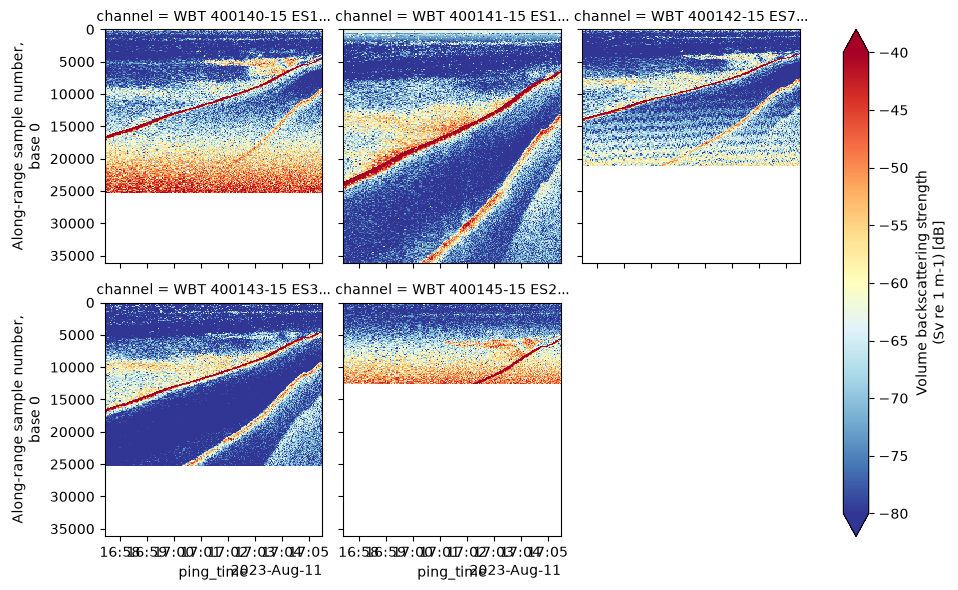

In [8]:
ds_Sv["Sv"].plot(
    x="ping_time", 
    row="channel", col_wrap=3,
    vmin=-80, vmax=-40,
    cmap="RdYlBu_r", yincrease=False
)

Adjust the colourbar range to highlight the seafloor.

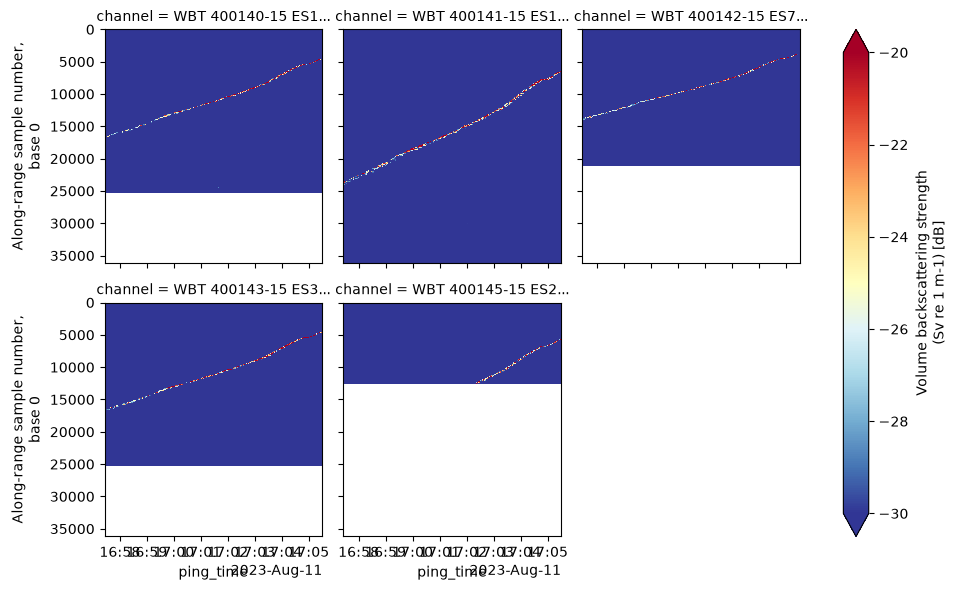

In [9]:
ds_Sv["Sv"].plot(
    x="ping_time", 
    row="channel", col_wrap=3,
    vmin=-30, vmax=-20,
    cmap="RdYlBu_r", yincrease=False
)

We show the 200 first samples, to observe the surface saturation zone. (We need to skip them to use the basic seafloor detection.)

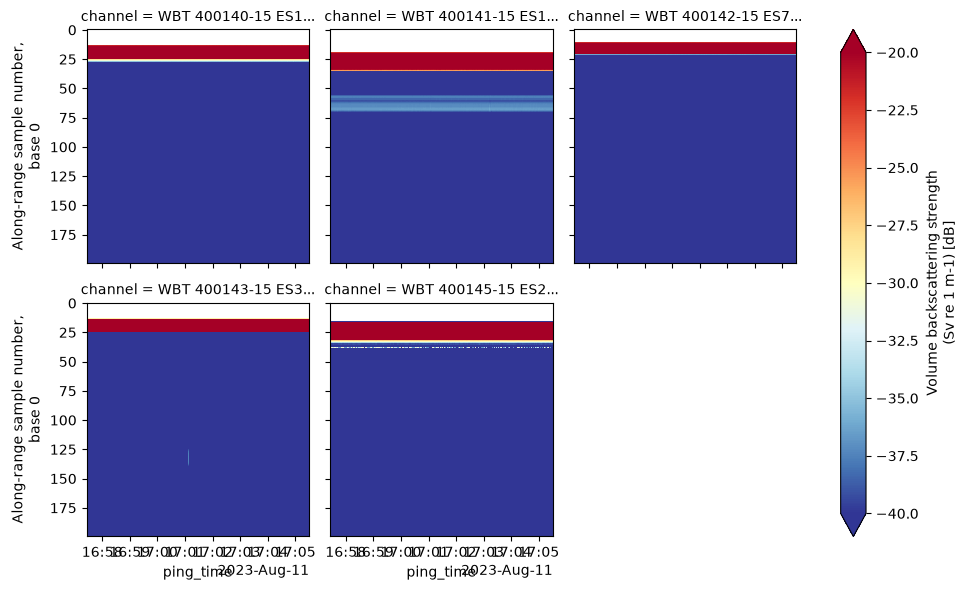

In [10]:
ds_Sv.isel(range_sample=slice(0, 200))["Sv"].plot(
    x="ping_time", 
    row="channel", 
    col_wrap=3,
    vmin=-40, vmax=-20,
    cmap="RdYlBu_r", 
    yincrease=False
)

# We detect seafloor with the mask subpackage

We use the basic bottom detection function from the seafloor_detection submodule within the echopype.mask package. We use here the 70 kHz channel to detect the seafloor.

In [11]:
sel_channel = "WBT 400142-15 ES70-7C_ES"

from echopype.mask import detect_seafloor
import xarray as xr

# call detect_seafloor dispatcher
basic_depth = detect_seafloor(
    ds_Sv,
    method="basic",
    params={
        "var_name": "Sv",
        "channel": sel_channel,
        "threshold": (-40, -20),
        "offset_m": 0.5,
        "bin_skip_from_surface": 200, # due to surface saturation
    },
)

# check output
assert isinstance(basic_depth, xr.DataArray)
assert set(basic_depth.dims) == {"ping_time"}
basic_depth

<xarray.DataArray 'bottom_depth' (ping_time: 213)> Size: 2kB
array([496.54757004, 495.62407996, 492.99568514, 490.75799766,
       488.80446096, 486.95748082, 486.03399074, 485.03946297,
       483.44111477, 481.52309693, 479.42748484, 478.18432512,
       475.98215649, 473.63791246, 471.61333807, 469.76635792,
       468.48767936, 467.38659504, 465.93032223, 464.36749288,
       462.87570122, 461.59702266, 459.60796712, 457.29924194,
       455.27466754, 452.11348999, 450.87033027, 447.88674696,
       445.47146523, 443.76656048, 441.81302379, 439.39774206,
       437.16005457, 435.13548018, 434.03439587, 431.58359529,
       429.80765284, 429.09727586, 426.29128679, 423.76944852,
       420.67930866, 419.0454416 , 416.13289599, 413.68209541,
       410.91162519, 408.8870508 , 406.68488217, 404.26960044,
       401.67672446, 400.2559705 , 398.62210345, 396.63304791,
       394.92814316, 393.15220071, 390.77243783, 388.92545769,
       387.14951524, 386.29706286, 384.76975236, 382.49654602,
       381.14682976, 379.90367005, 378.16324645, 376.10315321,
       374.54032386, 372.9774945 , 371.76985364, 369.7807981 ,
       367.9693368 , 365.76716816, 364.73712154, 363.95570687,
       362.92566025, 361.54042514, 359.69344499, 358.30820988,
       356.99401247, 355.43118312, 353.51316527, 352.02137362,
...
       274.41268864, 273.09849123, 271.74877497, 269.97283252,
       268.41000316, 266.88269266, 265.28434446, 262.94010042,
       261.23519567, 260.20514905, 258.81991395, 256.8308584 ,
       254.20246358, 251.57406876, 250.04675825, 247.88010847,
       245.67793983, 243.79544084, 241.27360256, 239.24902817,
       236.86926529, 234.16983277, 232.00318298, 229.83653319,
       227.38573262, 226.00049751, 223.51417808, 221.41856599,
       218.86120887, 216.65904023, 214.52790929, 212.5033349 ,
       210.51427936, 208.95145001, 206.67824367, 204.12088655,
       202.2028687 , 199.64551158, 197.79853143, 196.23570208,
       194.38872193, 192.29310984, 190.2330166 , 188.42155531,
       186.92976365, 184.58551962, 183.02269026, 181.31778551,
       179.08009803, 177.37519328, 175.45717544, 173.64571414,
       171.86977169, 170.59109313, 169.34793341, 169.06378262,
       168.92170723, 168.88618838, 168.2468491 , 167.71406636,
       167.00368938, 166.47090665, 165.33430348, 163.06109715,
       161.46274895, 160.61029657, 159.5447311 , 157.9463829 ,
       155.35350692, 152.54751786, 149.84808534, 148.28525598,
       146.86450202, 145.37271037, 144.73337109, 144.52025799,
       144.12955065])
Coordinates:
  * ping_time  (ping_time) datetime64[ns] 2kB 2023-08-11T16:57:27.277163 ... ...
Attributes:
    detector:               basic
    threshold_min:          -40.0
    threshold_max:          -20.0
    offset_m:               0.5
    bin_skip_from_surface:  200
    channel:                WBT 400142-15 ES70-7C_ES

In [12]:
print(type(basic_depth))  # xarray.DataArray
print(type(basic_depth.data))  # underlying NumPy or Dask array
basic_depth.coords

<class 'xarray.core.dataarray.DataArray'>
<class 'numpy.ndarray'>


Coordinates:
  * ping_time  (ping_time) datetime64[ns] 2kB 2023-08-11T16:57:27.277163 ... ...

We plot the seafloor. Accessing `.values` computes the result if it is Dask-backed.

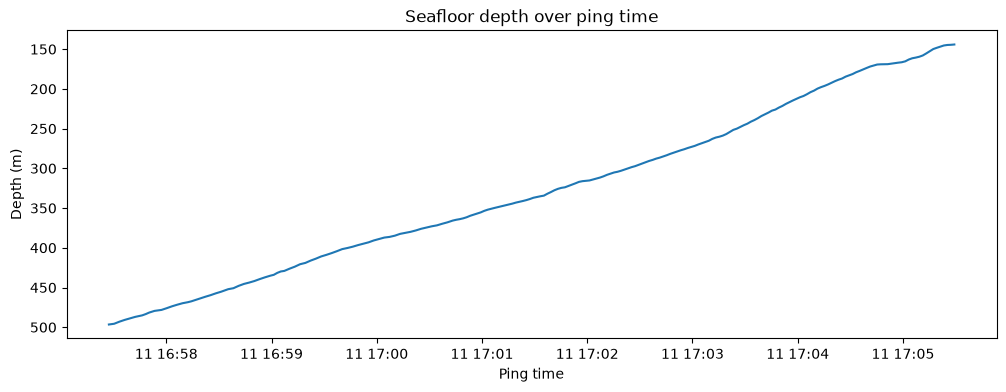

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(basic_depth["ping_time"].values, basic_depth.values, fillstyle='full', markersize=1)

ax.set_title("Seafloor depth over ping time")
ax.set_xlabel("Ping time")
ax.set_ylabel("Depth (m)")
ax.invert_yaxis()
plt.show()

basic_depth = basic_depth.compute()

### NumPy and Dask

The "basic" method supports both NumPy and Dask-backed inputs. We compare the same detection on one channel, using identical parameters. With Dask, computation is deferred until `.compute()`.

In [14]:
ds_numpy = ds_Sv[["Sv", "depth"]].sel(channel=[sel_channel]).compute()
ds_dask = ds_numpy.chunk({"ping_time": 64, "range_sample": 4096})

params = {
    "var_name": "Sv",
    "channel": sel_channel,
    "threshold": (-40, -20),
    "offset_m": 0.5,
    "bin_skip_from_surface": 200,
}

bottom_numpy = detect_seafloor(ds_numpy, method="basic", params=params)
bottom_dask = detect_seafloor(ds_dask, method="basic", params=params)

print("NumPy input/output:", type(ds_numpy.Sv.data), type(bottom_numpy.data))
print("Dask input/output:", type(ds_dask.Sv.data), type(bottom_dask.data))

xr.testing.assert_allclose(bottom_numpy, bottom_dask.compute())
del ds_numpy, ds_dask, bottom_numpy, bottom_dask, params

NumPy input/output: <class 'numpy.ndarray'> <class 'numpy.ndarray'>
Dask input/output: <class 'dask.array.core.Array'> <class 'dask.array.core.Array'>


### Missing detections

At 200 kHz, the seafloor is initially outside the recorded range. Basic returns NaN when no sample meets the detection criteria; other strong echoes can still cause false detections.

Missing detections at 70 kHz: 0
Missing detections at 200 kHz: 113


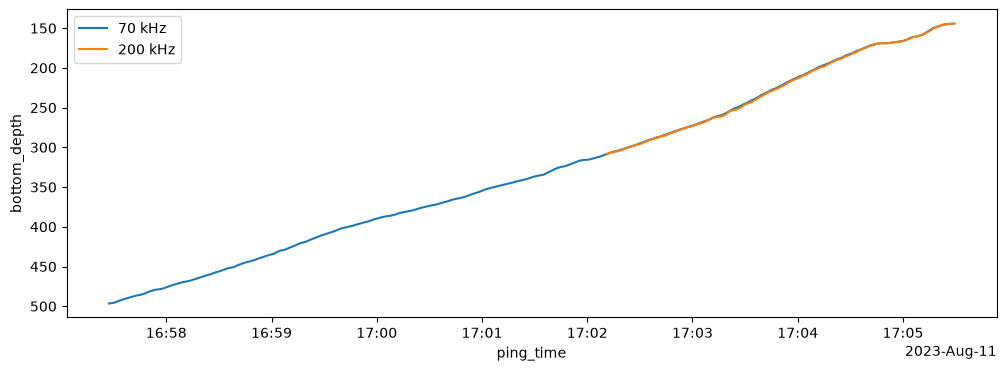

In [15]:
bottom_200 = detect_seafloor(
    ds_Sv, method="basic",
    params={
        "var_name": "Sv",
        "channel": "WBT 400145-15 ES200-7C_ES",
        "threshold": (-30, -20),
        "offset_m": 0.5,
        "bin_skip_from_surface": 200,
    },
).compute()

fig, ax = plt.subplots(figsize=(12, 4))
basic_depth.plot(ax=ax, label="70 kHz")
bottom_200.plot(ax=ax, label="200 kHz")
ax.invert_yaxis()
ax.legend()
print("Missing detections at 70 kHz:", basic_depth.isnull().sum().item())
print("Missing detections at 200 kHz:", bottom_200.isnull().sum().item())
del bottom_200

We compare the results with the Blackwell method, which requires the `angle_alongship` and `angle_athwartship` variables. Blackwell supports Dask-backed inputs but performs some intermediate computations eagerly. Both methods retrieve depth from each ping; Blackwell uses a reference depth profile to define the search bounds.

In [16]:
# add split-beam angles
ds_Sv = ep.consolidate.add_splitbeam_angle(
    ds_Sv,
    ed,
    waveform_mode="CW",
    encode_mode="power",
    to_disk=False,
)

required_vars = ["Sv", "angle_alongship", "angle_athwartship", "depth"]
missing = [var for var in required_vars if var not in ds_Sv]

if not missing:
    print("All required variables are present for Blackwell detection.")
else:
    print(f"Missing required variables: {missing}.")

del ed

All required variables are present for Blackwell detection.


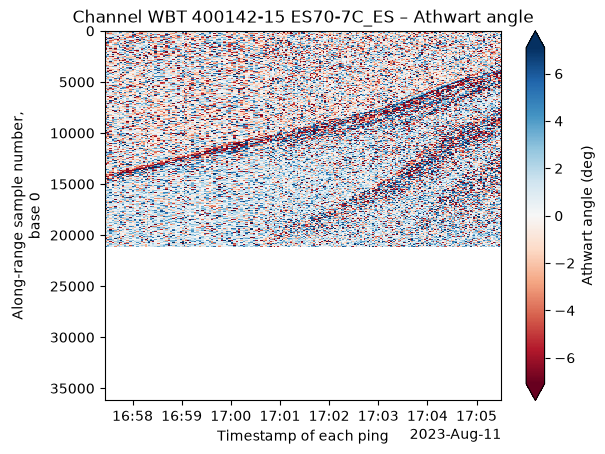

In [17]:
import matplotlib.pyplot as plt

ds_Sv["angle_athwartship"].sel(channel=sel_channel).plot(
    x="ping_time",
    y="range_sample",
    cmap="RdBu",
    yincrease=False,
    robust=True,
    cbar_kwargs={"label": "Athwart angle (deg)"}
)
plt.title(f"Channel {sel_channel} – Athwart angle")
plt.show()

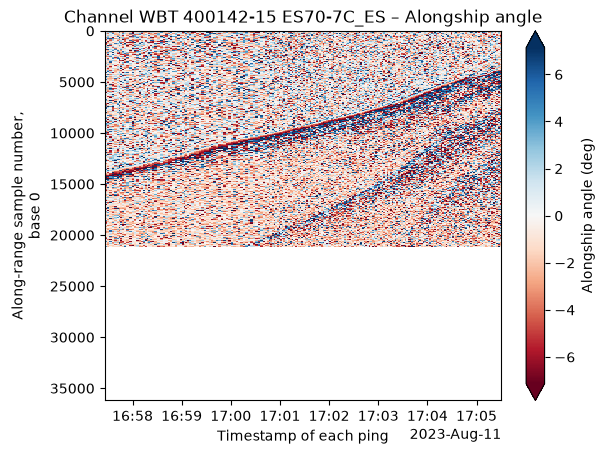

In [18]:
ds_Sv["angle_alongship"].sel(channel=sel_channel).plot(
    x="ping_time",
    y="range_sample",
    cmap="RdBu",
    yincrease=False,
    robust=True,
    cbar_kwargs={"label": "Alongship angle (deg)"}
)
plt.title(f"Channel {sel_channel} – Alongship angle")
plt.show()

We run the Blackwell seafloor detection:

In [19]:
blackwell_depth = detect_seafloor(
    ds=ds_Sv,
    method="blackwell",
    params={
        "channel": sel_channel,
        "var_name": "Sv",
        "threshold": (-40, 2.4, 1.0),
        "offset_m": 0.5,
        "r0": 10,
        "r1": 1000,
        "wtheta": 28,
        "wphi": 52,
    }
)

In [20]:
# check output
assert isinstance(blackwell_depth, xr.DataArray)
assert set(blackwell_depth.dims) == {"ping_time"}
blackwell_depth = blackwell_depth.compute()
blackwell_depth

<xarray.DataArray 'bottom_depth' (ping_time: 213)> Size: 2kB
array([496.54757004, 495.62407996, 492.99568514, 490.75799766,
       488.80446096, 486.95748082, 486.03399074, 485.03946297,
       483.44111477, 481.52309693, 479.42748484, 478.18432512,
       475.98215649, 473.63791246, 471.61333807, 469.76635792,
       468.48767936, 467.38659504, 465.93032223, 464.36749288,
       462.87570122, 461.59702266, 459.60796712, 457.29924194,
       455.27466754, 452.11348999, 450.87033027, 447.88674696,
       445.47146523, 443.76656048, 441.81302379, 439.39774206,
       437.16005457, 435.13548018, 434.03439587, 431.58359529,
       429.80765284, 429.09727586, 426.29128679, 423.76944852,
       420.67930866, 419.0454416 , 416.13289599, 413.68209541,
       410.91162519, 408.8870508 , 406.68488217, 404.26960044,
       401.67672446, 400.2559705 , 398.62210345, 396.63304791,
       394.92814316, 393.15220071, 390.77243783, 388.92545769,
       387.14951524, 386.29706286, 384.76975236, 382.49654602,
       381.14682976, 379.90367005, 378.16324645, 376.10315321,
       374.54032386, 372.9774945 , 371.76985364, 369.7807981 ,
       367.9693368 , 365.76716816, 364.73712154, 363.95570687,
       362.92566025, 361.54042514, 359.69344499, 358.30820988,
       356.99401247, 355.43118312, 353.51316527, 352.02137362,
...
       274.41268864, 273.09849123, 271.74877497, 269.97283252,
       268.41000316, 266.88269266, 265.28434446, 262.94010042,
       261.23519567, 260.20514905, 258.81991395, 256.8308584 ,
       254.20246358, 251.57406876, 250.04675825, 247.88010847,
       245.67793983, 243.79544084, 241.27360256, 239.24902817,
       236.86926529, 234.16983277, 232.00318298, 229.83653319,
       227.38573262, 226.00049751, 223.51417808, 221.41856599,
       218.86120887, 216.65904023, 214.52790929, 212.5033349 ,
       210.51427936, 208.95145001, 206.67824367, 204.12088655,
       202.2028687 , 199.64551158, 197.79853143, 196.23570208,
       194.38872193, 192.29310984, 190.2330166 , 188.42155531,
       186.92976365, 184.58551962, 183.02269026, 181.31778551,
       179.08009803, 177.37519328, 175.45717544, 173.64571414,
       171.86977169, 170.59109313, 169.34793341, 169.06378262,
       168.92170723, 168.88618838, 168.2468491 , 167.71406636,
       167.00368938, 166.47090665, 165.33430348, 163.06109715,
       161.46274895, 160.61029657, 159.5447311 , 157.9463829 ,
       155.35350692, 152.54751786, 149.84808534, 148.28525598,
       146.86450202, 145.37271037, 144.73337109, 144.52025799,
       144.3071449 ])
Coordinates:
  * ping_time  (ping_time) datetime64[ns] 2kB 2023-08-11T16:57:27.277163 ... ...
Attributes:
    detector:               blackwell
    threshold_Sv:           -40.0
    threshold_angle_major:  2.4
    threshold_angle_minor:  1.0
    offset_m:               0.5
    channel:                WBT 400142-15 ES70-7C_ES

We compare the results from both seafloor detection methods.

In [ ]:
# get the ping_time values from each DataArray
pt_basic = basic_depth.ping_time
pt_blackwell = blackwell_depth.ping_time

# find ping times in basic_depth but not in blackwell_depth
missing_in_blackwell = pt_basic[~pt_basic.isin(pt_blackwell)]
print(f"Ping times in basic_depth but missing in blackwell_depth: {missing_in_blackwell.size}")
print(missing_in_blackwell.values)

# find ping times in blackwell_depth but not in basic_depth
missing_in_basic = pt_blackwell[~pt_blackwell.isin(pt_basic)]
print(f"Ping times in blackwell_depth but missing in basic_depth: {missing_in_basic.size}")
print(missing_in_basic.values)

Ping times in basic_depth but missing in blackwell_depth: 0
[]
Ping times in blackwell_depth but missing in basic_depth: 0
[]


In [ ]:
print("bd.ping_time:", basic_depth)
print("\n\n")
print("bw.ping_time:", blackwell_depth)

bd.ping_time: <xarray.DataArray 'bottom_depth' (ping_time: 213)> Size: 2kB
array([496.54757004, 495.62407996, 492.99568514, 490.75799766,
       488.80446096, 486.95748082, 486.03399074, 485.03946297,
       483.44111477, 481.52309693, 479.42748484, 478.18432512,
       475.98215649, 473.63791246, 471.61333807, 469.76635792,
       468.48767936, 467.38659504, 465.93032223, 464.36749288,
       462.87570122, 461.59702266, 459.60796712, 457.29924194,
       455.27466754, 452.11348999, 450.87033027, 447.88674696,
       445.47146523, 443.76656048, 441.81302379, 439.39774206,
       437.16005457, 435.13548018, 434.03439587, 431.58359529,
       429.80765284, 429.09727586, 426.29128679, 423.76944852,
       420.67930866, 419.0454416 , 416.13289599, 413.68209541,
       410.91162519, 408.8870508 , 406.68488217, 404.26960044,
       401.67672446, 400.2559705 , 398.62210345, 396.63304791,
       394.92814316, 393.15220071, 390.77243783, 388.92545769,
       387.14951524, 386.29706286, 384.7697

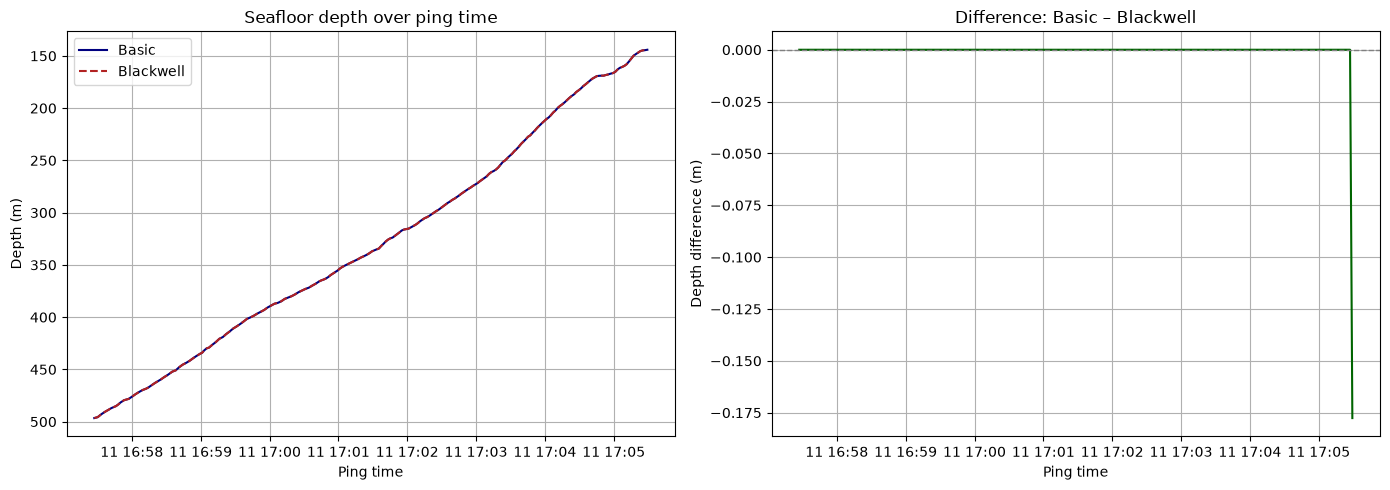

In [ ]:
# align both bottom detections on ping_time using xarray
bd, bw = xr.align(basic_depth, blackwell_depth, join="inner")
assert bd.ping_time.equals(bw.ping_time), "Ping times are not aligned."

# compute difference
diff = bd - bw
common_time = bd.ping_time  # aligned time axis, pick any

# plot
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), sharex=True)

# p1: depth from both methods
axs[0].plot(common_time, bd, label="Basic", color="navy")
axs[0].plot(common_time, bw, label="Blackwell", color="firebrick", linestyle="--")
axs[0].invert_yaxis()
axs[0].set_title("Seafloor depth over ping time")
axs[0].set_xlabel("Ping time")
axs[0].set_ylabel("Depth (m)")
axs[0].legend()
axs[0].grid(True)

# p2: difference
axs[1].plot(common_time, diff, color="darkgreen")
axs[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axs[1].set_title("Difference: Basic – Blackwell")
axs[1].set_xlabel("Ping time")
axs[1].set_ylabel("Depth difference (m)")
axs[1].grid(True)

plt.tight_layout()
plt.show()

In [24]:
# Show last 10 values of each
print("Last 10 bottom_depth values (Basic):")
print(bd.values[-10:])

print("\nLast 10 blackwell_bottom values (Blackwell):")
print(bw.values[-10:])

del bd, bw, diff, common_time, pt_basic, pt_blackwell, missing_in_basic, missing_in_blackwell, basic_depth

Last 10 bottom_depth values (Basic):
[157.9463829  155.35350692 152.54751786 149.84808534 148.28525598
 146.86450202 145.37271037 144.73337109 144.52025799 144.12955065]

Last 10 blackwell_bottom values (Blackwell):
[157.9463829  155.35350692 152.54751786 149.84808534 148.28525598
 146.86450202 145.37271037 144.73337109 144.52025799 144.3071449 ]


Next, we aim to mask the seafloor in ds_Sv.

The echoregions package expects an xarray.DataArray as input, with depth provided. However, in raw Sv datasets like ds_Sv, depth is typically stored as a data variable, not a coordinate.
As a result, directly passing ds_Sv["Sv"] to lines() does not work, because the depth information is not attached to the Sv DataArray.

As a temporary workaround, we create a new Dataset (ds_single) where depth is explicitly defined as a coordinate. This allows Sv to be treated as a proper 2D DataArray over (ping_time, depth) for a single channel, as required by echoregions for bottom masking and region selection.

This conversion assumes a common depth grid across pings for this example.

In [25]:
import xarray as xr

selected_channel = "WBT 400141-15 ES18_ES"
frequency_dict = {
    "WBT 400140-15 ES120-7C_ES": 120000,
    "WBT 400141-15 ES18_ES": 18000,
    "WBT 400142-15 ES70-7C_ES": 70000,
    "WBT 400143-15 ES38B_ES": 38000,
    "WBT 400145-15 ES200-7C_ES": 200000,
}

# Extract Sv, time, and depth (first ping)
Sv_da = ds_Sv["Sv"].sel(channel=selected_channel)
depth = ds_Sv["depth"].sel(channel=selected_channel).isel(ping_time=0)

# Build DataArray with (ping_time, depth) and add channel dim
Sv_plot = xr.DataArray(
    data=Sv_da.values,
    dims=["ping_time", "depth"],
    coords={"ping_time": Sv_da["ping_time"], "depth": depth.data},
    name="Sv"
).expand_dims(channel=[selected_channel])

# Wrap into Dataset and add frequency_nominal
ds_single = xr.Dataset({
    "Sv": Sv_plot,
    "frequency_nominal": xr.DataArray([frequency_dict[selected_channel]], dims=["channel"], coords={"channel": [selected_channel]})
})

del ds_Sv, Sv_da, Sv_plot, depth, frequency_dict

In [26]:
ds_single

<xarray.Dataset> Size: 62MB
Dimensions:            (channel: 1, ping_time: 213, depth: 36198)
Coordinates:
  * channel            (channel) object 8B 'WBT 400141-15 ES18_ES'
  * ping_time          (ping_time) datetime64[ns] 2kB 2023-08-11T16:57:27.277...
  * depth              (depth) float64 290kB 9.8 9.821 9.841 ... 759.8 759.8
Data variables:
    Sv                 (channel, ping_time, depth) float64 62MB nan ... -70.16
    frequency_nominal  (channel) int64 8B 18000

We can now use echoregions to generate a mask from the detected seafloor line. (Note: the mask is applied here only to a single frequency.)

In [27]:
import pandas as pd

# Create minimal DataFrame with required columns
df = pd.DataFrame({
    "time": blackwell_depth["ping_time"].values,
    "depth": blackwell_depth.values,
})

# Save to CSV (required at the moment)
df.to_csv("./example_data/seafloor_detection/bottom_depth_minimal.csv", index=False)

del df, blackwell_depth

In [28]:
import echoregions as er

lines = er.read_lines_csv("./example_data/seafloor_detection/bottom_depth_minimal.csv")

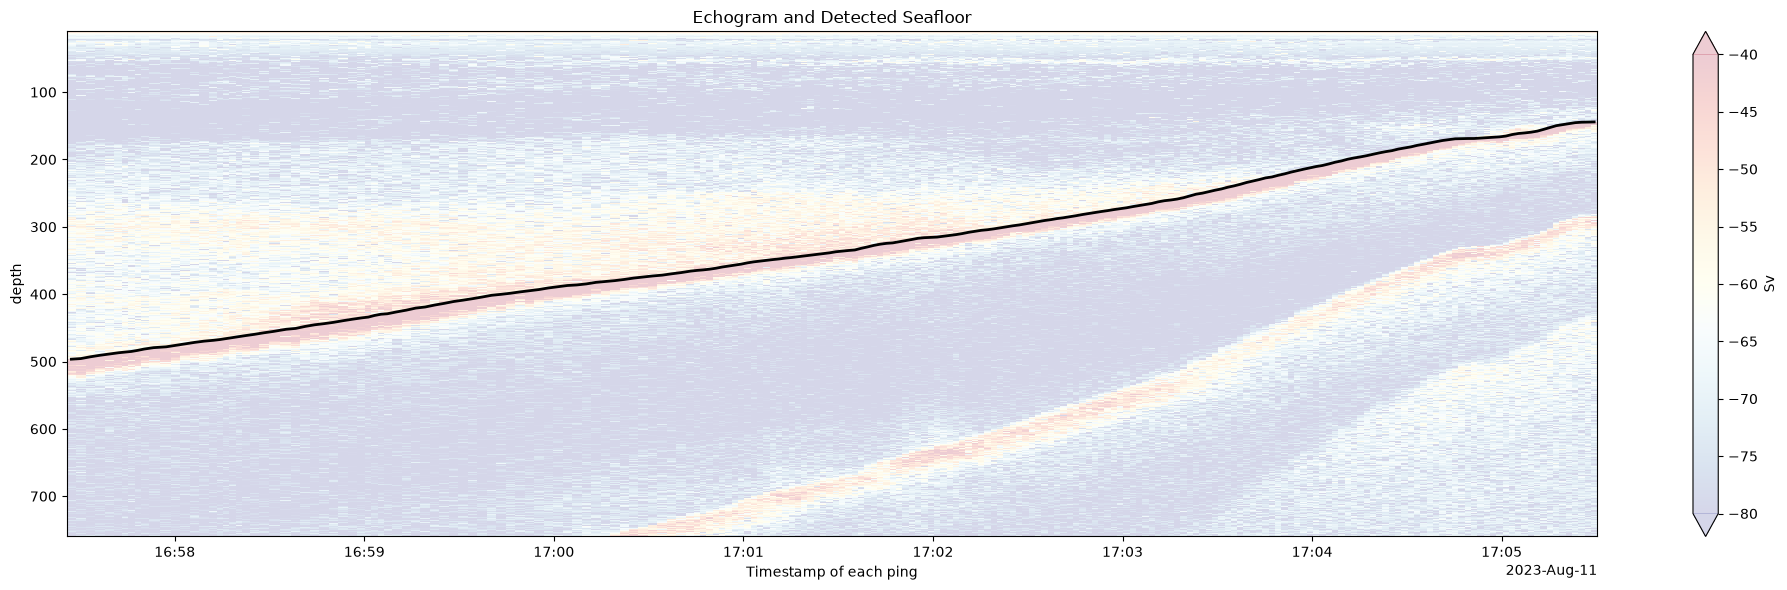

In [29]:
plt.figure(figsize=(20, 6))

# Plot Sv echogram for one channel
ds_single["Sv"].isel(channel=0).T.plot.pcolormesh(
    y="depth",
    cmap="RdYlBu_r",
    yincrease=False,
    vmin=-80,
    vmax=-40,
    alpha=0.2
)

# Plot seafloor line from echoregions Lines object
plt.plot(
    lines.data['time'], lines.data['depth'], 
    color='black', label='Bottom', linewidth=2
)

plt.title("Echogram and Detected Seafloor")
plt.tight_layout()
plt.show()


In [30]:
# Use the built in mask function
bottom_mask_da, bottom_points = lines.seafloor_mask(
    ds_single.Sv, # Pass a DataArray where depth is a coordinate
    operation="above_below",
    method="slinear",
    limit_area=None,
    limit_direction="both"
)

bottom_mask_da

<xarray.DataArray (depth: 36198, ping_time: 213)> Size: 62MB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1]], shape=(36198, 213))
Coordinates:
  * depth      (depth) float64 290kB 9.8 9.821 9.841 9.862 ... 759.7 759.8 759.8
  * ping_time  (ping_time) datetime64[ns] 2kB 2023-08-11T16:57:27.277163 ... ...

In [31]:
import numpy as np
print("Unique Values in Bottom Mask:", np.unique(bottom_mask_da.data))

Unique Values in Bottom Mask: [0 1]


In [32]:
print("Bottom Mask Ping Time Dimension Length:", len(bottom_mask_da["ping_time"]))
print("Bottom Mask Depth Dimension Length:", len(bottom_mask_da["depth"]))
print("Echogram Ping Time Dimension Length:", len(ds_single.Sv["ping_time"]))
print("Echogram Depth Dimension Length:", len(ds_single.Sv["depth"]))

Bottom Mask Ping Time Dimension Length: 213
Bottom Mask Depth Dimension Length: 36198
Echogram Ping Time Dimension Length: 213
Echogram Depth Dimension Length: 36198


We plot the mask.

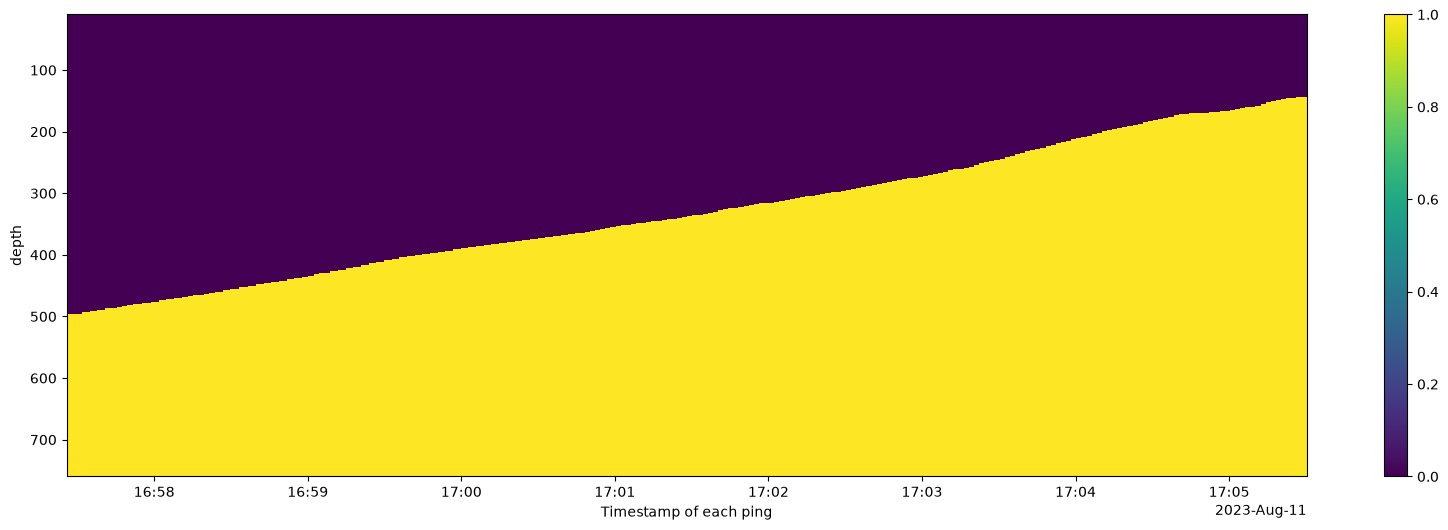

In [33]:
plt.figure(figsize = (20, 6))
bottom_mask_da.plot(y="depth", yincrease=False)

In [34]:
# Invert 1/0 or True/False mask to match echopype apply_mask expectations
inverted_mask = ~bottom_mask_da.astype(bool)

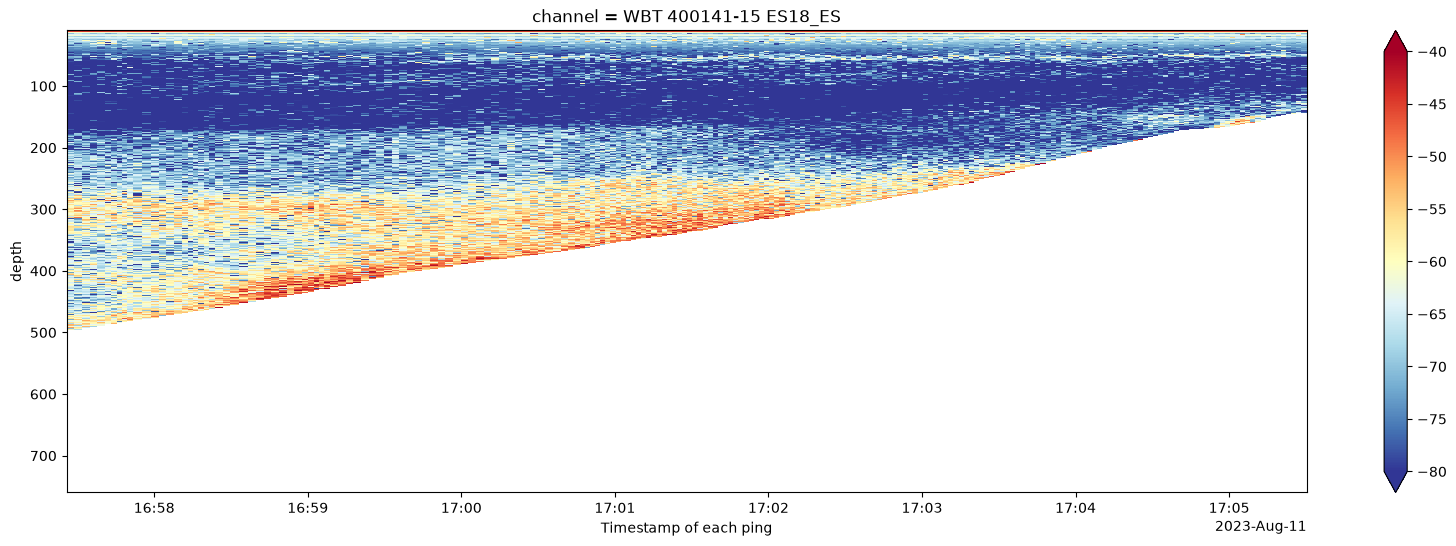

In [35]:
import echopype as ep

# Get only channel values where the mask is 1
mask_exists_Sv = xr.where(
    inverted_mask == 1,
    ds_single["Sv"].isel(channel=0),
    np.nan,
)

# Plot the masked Sv
plt.figure(figsize = (20, 6))
mask_exists_Sv.plot(y="depth", cmap="RdYlBu_r", yincrease=False, vmin=-80, vmax=-40)

del mask_exists_Sv

We use apply_mask from the echopype.mask to the dataset

In [36]:
from echopype.mask import apply_mask
import numpy as np

print(ds_single["Sv"].dims)
print(ds_single["Sv"].shape)
print(inverted_mask.dims)
print(inverted_mask.shape)

# Transpose to match ('ping_time', 'depth')
bottom_mask_fixed = inverted_mask.transpose("ping_time", "depth")

print(ds_single["Sv"].dims)
print(ds_single["Sv"].shape)
print(bottom_mask_fixed.dims)
print(bottom_mask_fixed.shape)

ds_with_mask = apply_mask(ds_single, bottom_mask_fixed, var_name="Sv", fill_value=np.nan)

del ds_single, inverted_mask, bottom_mask_fixed, bottom_mask_da, bottom_points, lines

('channel', 'ping_time', 'depth')
(1, 213, 36198)
('depth', 'ping_time')
(36198, 213)
('channel', 'ping_time', 'depth')
(1, 213, 36198)
('ping_time', 'depth')
(213, 36198)
xarray Dataset does not contain valid location data. Processing level attributes will not be added.


In [37]:
ds_with_mask

<xarray.Dataset> Size: 62MB
Dimensions:            (channel: 1, ping_time: 213, depth: 36198)
Coordinates:
  * channel            (channel) object 8B 'WBT 400141-15 ES18_ES'
  * ping_time          (ping_time) datetime64[ns] 2kB 2023-08-11T16:57:27.277...
  * depth              (depth) float64 290kB 9.8 9.821 9.841 ... 759.8 759.8
Data variables:
    Sv                 (channel, ping_time, depth) float64 62MB nan nan ... nan
    frequency_nominal  (channel) int64 8B 18000
Attributes:
    mask_software_name:     echopype
    mask_software_version:  0.12.1.dev16+g52c4301f6.d20261118
    mask_time:              2026-11-19T22:03:19+00:00
    mask_function:          mask.apply_mask

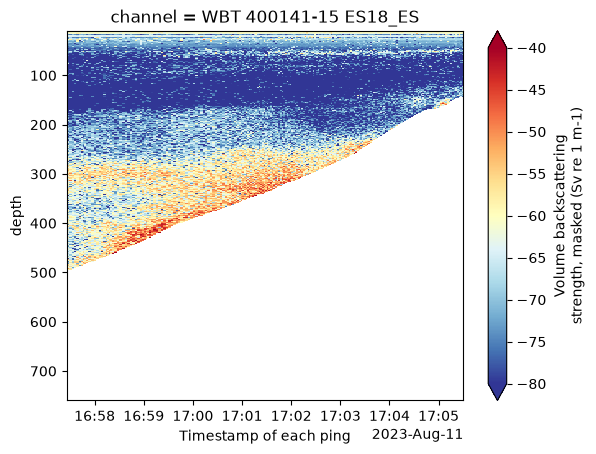

In [38]:
ds_with_mask["Sv"].plot(
    x="ping_time", 
    vmin=-80, vmax=-40,
    cmap="RdYlBu_r", yincrease=False
)

We compute and plot MVBS using the mask computed with the mask subpackage.

xarray Dataset does not contain valid location data. Processing level attributes will not be added.


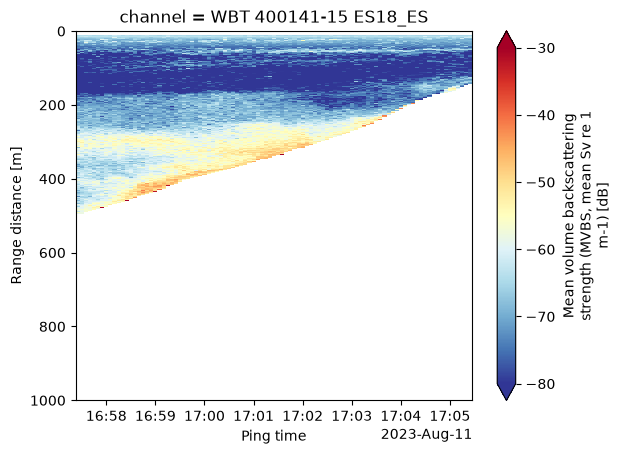

In [39]:
# Compute MVBS
ds_MVBS_mask = ep.commongrid.compute_MVBS(
    ds_with_mask,
    range_var="depth",
    range_bin="1m",
    ping_time_bin="5s",
    range_var_max="1000m",
)

ds_MVBS_mask["Sv"].plot(
    x="ping_time", cmap='RdYlBu_r', yincrease=False,
    vmin=-80, vmax=-30
)

End of notebook.